<a href="https://colab.research.google.com/github/Deangr-econ/Stock_volatility/blob/main/Stock_Vol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

cov = pd.read_csv("/content/drive/Othercomputers/My Laptop/Documents/Maastricht University/Master/Thesis/Volare Data/realized_covariance_stocks_20261030/realized_covariance_stocks_20261030.csv")
cov['date'] = pd.to_datetime(cov['date'])
cov.info()
print(f"Nan-Values:",cov.isna().sum().sum())

# Filter out duplicate pairs since Cov(A, B) = Cov(B, A)
# We'll keep only pairs where asset1 <= asset2 to avoid redundant columns
cov_filtered = cov[cov['asset1'] <= cov['asset2']].copy()

# Create a unique feature column name for each covariance combination
cov_filtered['pair'] = cov_filtered['asset1'] + "_" + cov_filtered['asset2']

# Pivot the dataset: rows = date, columns = pair, values = rcov
X_df = cov_filtered.pivot(index='date', columns='pair', values='rcov')

# Check for any remaining missing values (if any asset pair was missing on a specific date)
missing_count = X_df.isna().sum().sum()
if missing_count > 0:
    # Forward fill then backward fill to handle any isolated missing values safely
    X_df = X_df.ffill().bfill()

print(f"X Matrix shape: {X_df.shape} (Rows/Dates: {X_df.shape[0]}, Columns/Pairs: {X_df.shape[1]})")
print(f"Number of imputed missing values: {missing_count}")

# Display the first few rows of the transformed design matrix
X_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2439500 entries, 0 to 2439499
Data columns (total 9 columns):
 #   Column    Dtype         
---  ------    -----         
 0   date      datetime64[ns]
 1   asset1    object        
 2   asset2    object        
 3   rcov      float64       
 4   rbpcov    float64       
 5   rscov_p   float64       
 6   rscov_n   float64       
 7   rscov_mp  float64       
 8   rscov_mn  float64       
dtypes: datetime64[ns](1), float64(6), object(2)
memory usage: 167.5+ MB
Nan-Values: 0
X Matrix shape: (2975, 820) (Rows/Dates: 2975, Columns/Pairs: 820)
Number of imputed missing values: 0


pair,AAPL_AAPL,AAPL_ADBE,AAPL_AMD,AAPL_AMGN,AAPL_AMZN,AAPL_AXP,AAPL_BA,AAPL_CAT,AAPL_CRM,AAPL_CSCO,...,VZ_VZ,VZ_WMT,VZ_XOM,V_V,V_VZ,V_WMT,V_XOM,WMT_WMT,WMT_XOM,XOM_XOM
date,,,,,,,,,,,,,,,,,,,,,
2015-01-02,0.000275,0.000086,0.000075,0.000120,0.000092,0.000086,0.000051,0.000056,0.000125,0.000096,...,0.000093,0.000032,0.000034,0.000226,0.000039,0.000039,0.000020,0.000080,0.000021,0.000160
2015-01-05,0.000278,0.000111,0.000042,0.000143,0.000084,0.000093,0.000078,0.000035,0.000165,0.000134,...,0.000101,0.000030,0.000029,0.000145,0.000023,0.000047,0.000041,0.000095,0.000031,0.000180
2015-01-06,0.000370,0.000144,0.000102,0.000208,0.000166,0.000141,0.000100,0.000115,0.000200,0.000143,...,0.000166,0.000050,0.000028,0.000239,0.000047,0.000058,0.000088,0.000120,0.000047,0.000228
2015-01-07,0.000210,0.000117,0.000046,0.000154,0.000129,0.000105,0.000067,0.000090,0.000166,0.000120,...,0.000115,0.000040,0.000048,0.000138,0.000051,0.000060,0.000058,0.000134,0.000044,0.000191
2015-01-08,0.000146,0.000047,-0.000046,0.000007,0.000018,0.000026,0.000022,0.000018,0.000050,0.000021,...,0.000101,0.000016,0.000027,0.000098,0.000024,0.000014,0.000024,0.000112,0.000013,0.000141


In [7]:
X_df.columns

Index(['AAPL_AAPL', 'AAPL_ADBE', 'AAPL_AMD', 'AAPL_AMGN', 'AAPL_AMZN',
       'AAPL_AXP', 'AAPL_BA', 'AAPL_CAT', 'AAPL_CRM', 'AAPL_CSCO',
       ...
       'VZ_VZ', 'VZ_WMT', 'VZ_XOM', 'V_V', 'V_VZ', 'V_WMT', 'V_XOM', 'WMT_WMT',
       'WMT_XOM', 'XOM_XOM'],
      dtype='object', name='pair', length=820)

In [11]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

class FactorModelEvaluator:
    """
    An OOP-style Evaluator to run out-of-sample factor forecasting evaluations
    using either expanding or rolling window approaches, decoupling calculation of error matrices
    from their subsequent metrics evaluation and plotting.
    """
    def __init__(self, df, r_max=820, n_eval=800, window_size=1000):
        self.df = df
        self.r_max = r_max
        self.n_eval = n_eval
        self.window_size = window_size
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.eval_dates = df.index[-n_eval:]

    def compute_expanding_errors(self):
        """
        Runs expanding window SVD and regression, returning a dictionary of
        error DataFrames (Actual - Forecast) indexed by evaluation dates for each r.
        """
        print(f"Computing expanding window errors on: {self.device}")
        # Use original covariance scale directly without taking log
        X_raw = torch.tensor(self.df.values, dtype=torch.float32, device=self.device)
        T, N = X_raw.shape
        start_idx = T - self.n_eval

        errors_accumulator = {r: [] for r in range(1, self.r_max + 1)}

        for t in range(start_idx, T):
            X_win = X_raw[:t]
            mean_t = X_win.mean(dim=0, keepdim=True)
            std_t = X_win.std(dim=0, keepdim=True)
            # Guard against division by zero
            std_t = torch.clamp(std_t, min=1e-8)
            X_norm = (X_win - mean_t) / std_t
            x_actual_norm = (X_raw[t : t + 1] - mean_t) / std_t

            # SVD
            U, S, _ = torch.linalg.svd(X_norm, full_matrices=False)
            F_full = U[:, :self.r_max] * S[:self.r_max].unsqueeze(0)

            F_train = F_full[:-1, :]
            Y_train = X_norm[1:, :]
            f_latest = F_full[-1:, :]

            # OLS prep
            FtF = F_train.T @ F_train
            FtY = F_train.T @ Y_train

            for r in range(1, self.r_max + 1):
                A = FtF[:r, :r]
                Beta_r = torch.linalg.solve(A, FtY[:r, :])
                x_pred = f_latest[:, :r] @ Beta_r
                err = (x_actual_norm - x_pred).cpu().numpy()[0]
                errors_accumulator[r].append(err)

        errors_by_r = {
            r: pd.DataFrame(errors_accumulator[r], index=self.eval_dates, columns=self.df.columns)
            for r in range(1, self.r_max + 1)
        }
        return errors_by_r

    def compute_rolling_errors(self):
        """
        Runs rolling window SVD and regression, returning a dictionary of
        error DataFrames (Actual - Forecast) indexed by evaluation dates for each r.
        """
        print(f"Computing rolling window errors on: {self.device}")
        df_aligned = self.df.iloc[-(self.window_size + self.n_eval) :]

        # Use original covariance scale directly without taking log
        raw_tensor = torch.tensor(df_aligned.values, dtype=torch.float32, device=self.device)

        # Unfold into rolling windows: shape (B, W, N)
        X_raw_batched = raw_tensor.unfold(0, self.window_size, 1).permute(0, 2, 1)[:-1].contiguous()
        B, W, N = X_raw_batched.shape

        # 2. Compute mean and std strictly INSIDE each window (along dim=1)
        win_mean = X_raw_batched.mean(dim=1, keepdim=True)              # (B, 1, N)
        win_std = X_raw_batched.std(dim=1, unbiased=True, keepdim=True) # (B, 1, N)

        # Guard against division by zero
        win_std = torch.clamp(win_std, min=1e-8)

        # 3. Standardize each window using ONLY its own historical stats
        X_batched = (X_raw_batched - win_mean) / win_std

        # 4. Standardize the out-of-sample target using the SAME window's stats
        X_actual_raw = raw_tensor[self.window_size:, :].unsqueeze(1)    # (B, 1, N)
        X_actual = (X_actual_raw - win_mean) / win_std

        # Proceed with SVD & Regression as before
        U_batched, S_batched, _ = torch.linalg.svd(X_batched, full_matrices=False)
        Y_train = X_batched[:, 1:, :]

        errors_by_r = {}
        for r in range(1, self.r_max + 1):
            F_batched = U_batched[:, :, :r] * S_batched[:, :r].unsqueeze(1)
            F_train = F_batched[:, :-1, :]
            F_latest = F_batched[:, -1:, :]

            Ft = F_train.transpose(1, 2)
            FtF = torch.bmm(Ft, F_train)
            FtY = torch.bmm(Ft, Y_train)

            # Directly invert or solve since the batches are clean
            Beta = torch.bmm(torch.linalg.inv(FtF), FtY)
            X_pred = torch.bmm(F_latest, Beta)

            err_tensor = (X_actual - X_pred).squeeze(1).cpu().numpy()
            errors_by_r[r] = pd.DataFrame(err_tensor, index=self.eval_dates, columns=self.df.columns)

        return errors_by_r

    @staticmethod
    def evaluate_performance(errors_by_r, start_idx=0, end_idx=None):
        """
        Computes out-of-sample performance (RMSE and MAE) across a specific sub-window
        of the predictions (e.g. first 600 days for validation, or last 200 days for test).
        """
        metrics = []
        for r, err_df in errors_by_r.items():
            # Slice the errors to the desired sub-window
            err_vals = err_df.iloc[start_idx:end_idx].values
            rmse = np.sqrt(np.mean(err_vals ** 2))
            mae = np.mean(np.abs(err_vals))
            metrics.append({'r': r, 'RMSE': rmse, 'MAE': mae})
        return pd.DataFrame(metrics).set_index('r')

In [12]:
# Initialize our Decoupled Evaluator
evaluator = FactorModelEvaluator(X_df, r_max=820, n_eval=800, window_size=500)

# 1. First step: Generate pure error matrices across the last 800 observations
exp_errors = evaluator.compute_expanding_errors()
roll_errors = evaluator.compute_rolling_errors()

# 2. Second step: Evaluate on the first 600 observations (validation window) to choose r
exp_val_metrics = evaluator.evaluate_performance(exp_errors, start_idx=0, end_idx=600)
roll_val_metrics = evaluator.evaluate_performance(roll_errors, start_idx=0, end_idx=600)

# Find the optimal specifications based on the validation window
best_exp_r = exp_val_metrics['RMSE'].idxmin()
best_roll_r = roll_val_metrics['RMSE'].idxmin()

print(f"\n--- Validation Selection (First 600 Days of Test Window) ---")
print(f"Optimal Expanding Window: r = {best_exp_r} (Val RMSE = {exp_val_metrics.loc[best_exp_r, 'RMSE']:.5f})")
print(f"Optimal Rolling Window:   r = {best_roll_r} (Val RMSE = {roll_val_metrics.loc[best_roll_r, 'RMSE']:.5f})")

# 3. Third step: Evaluate selected optimal models on the last 200 observations (final test window)
exp_test_metrics = evaluator.evaluate_performance(exp_errors, start_idx=600, end_idx=800)
roll_test_metrics = evaluator.evaluate_performance(roll_errors, start_idx=600, end_idx=800)

test_rmse_exp = exp_test_metrics.loc[best_exp_r, 'RMSE']
test_mae_exp = exp_test_metrics.loc[best_exp_r, 'MAE']

test_rmse_roll = roll_test_metrics.loc[best_roll_r, 'RMSE']
test_mae_roll = roll_test_metrics.loc[best_roll_r, 'MAE']

print(f"\n--- Final Evaluation (Last 200 Days of Test Window) ---")
print(f"Optimal Expanding Model (r={best_exp_r}) -> Test RMSE: {test_rmse_exp:.5f}, Test MAE: {test_mae_exp:.5f}")
print(f"Optimal Rolling Model   (r={best_roll_r}) -> Test RMSE: {test_rmse_roll:.5f}, Test MAE: {test_mae_roll:.5f}")

Computing expanding window errors on: cpu


KeyboardInterrupt: 

=== Validation Split Performance Comparison (First 600 Days) ===


,Best r (Val RMSE),Min Val RMSE,Best r (Val MAE),Min Val MAE
Method,,,,
Rolling (1000d),17,0.784266,24,0.591171
Expanding,38,0.641472,38,0.476253


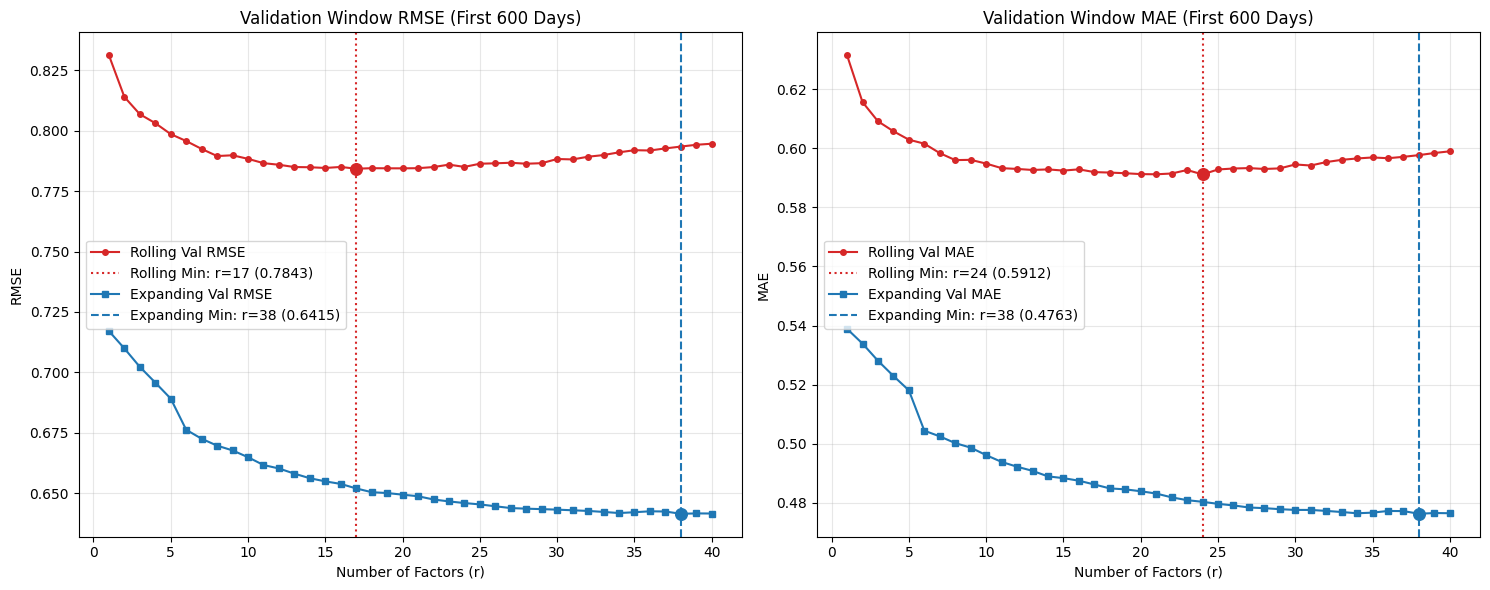

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Build a summary table using the validation phase metrics
summary = pd.DataFrame({
    'Method': ['Rolling (1000d)', 'Expanding'],
    'Best r (Val RMSE)': [
        roll_val_metrics['RMSE'].idxmin(),
        exp_val_metrics['RMSE'].idxmin(),
    ],
    'Min Val RMSE': [
        roll_val_metrics['RMSE'].min(),
        exp_val_metrics['RMSE'].min(),
    ],
    'Best r (Val MAE)': [
        roll_val_metrics['MAE'].idxmin(),
        exp_val_metrics['MAE'].idxmin(),
    ],
    'Min Val MAE': [
        roll_val_metrics['MAE'].min(),
        exp_val_metrics['MAE'].min(),
    ],
}).set_index('Method')

print('=== Validation Split Performance Comparison (First 600 Days) ===')
display(summary)

# 2. Side-by-side validation error curves (RMSE & MAE) to show how optimal r was selected
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)

# --- Subplot 1: Validation RMSE ---
r_roll_rmse = roll_val_metrics['RMSE'].idxmin()
v_roll_rmse = roll_val_metrics.loc[r_roll_rmse, 'RMSE']
r_exp_rmse = exp_val_metrics['RMSE'].idxmin()
v_exp_rmse = exp_val_metrics.loc[r_exp_rmse, 'RMSE']

axes[0].plot(
    roll_val_metrics.index,
    roll_val_metrics['RMSE'],
    marker='o',
    markersize=4,
    color='tab:red',
    label='Rolling Val RMSE',
)
axes[0].axvline(
    r_roll_rmse,
    color='tab:red',
    linestyle=':',
    linewidth=1.5,
    label=f'Rolling Min: r={r_roll_rmse} ({v_roll_rmse:.4f})',
)
axes[0].scatter([r_roll_rmse], [v_roll_rmse], color='tab:red', s=70, zorder=5)

axes[0].plot(
    exp_val_metrics.index,
    exp_val_metrics['RMSE'],
    marker='s',
    markersize=4,
    color='tab:blue',
    label='Expanding Val RMSE',
)
axes[0].axvline(
    r_exp_rmse,
    color='tab:blue',
    linestyle='--',
    linewidth=1.5,
    label=f'Expanding Min: r={r_exp_rmse} ({v_exp_rmse:.4f})',
)
axes[0].scatter([r_exp_rmse], [v_exp_rmse], color='tab:blue', s=70, zorder=5)

axes[0].set_title('Validation Window RMSE (First 600 Days)')
axes[0].set_xlabel('Number of Factors (r)')
axes[0].set_ylabel('RMSE')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# --- Subplot 2: Validation MAE ---
r_roll_mae = roll_val_metrics['MAE'].idxmin()
v_roll_mae = roll_val_metrics.loc[r_roll_mae, 'MAE']
r_exp_mae = exp_val_metrics['MAE'].idxmin()
v_exp_mae = exp_val_metrics.loc[r_exp_mae, 'MAE']

axes[1].plot(
    roll_val_metrics.index,
    roll_val_metrics['MAE'],
    marker='o',
    markersize=4,
    color='tab:red',
    label='Rolling Val MAE',
)
axes[1].axvline(
    r_roll_mae,
    color='tab:red',
    linestyle=':',
    linewidth=1.5,
    label=f'Rolling Min: r={r_roll_mae} ({v_roll_mae:.4f})',
)
axes[1].scatter([r_roll_mae], [v_roll_mae], color='tab:red', s=70, zorder=5)

axes[1].plot(
    exp_val_metrics.index,
    exp_val_metrics['MAE'],
    marker='s',
    markersize=4,
    color='tab:blue',
    label='Expanding Val MAE',
)
axes[1].axvline(
    r_exp_mae,
    color='tab:blue',
    linestyle='--',
    linewidth=1.5,
    label=f'Expanding Min: r={r_exp_mae} ({v_exp_mae:.4f})',
)
axes[1].scatter([r_exp_mae], [v_exp_mae], color='tab:blue', s=70, zorder=5)

axes[1].set_title('Validation Window MAE (First 600 Days)')
axes[1].set_xlabel('Number of Factors (r)')
axes[1].set_ylabel('MAE')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# 1. Setup Data and Configurations - using X_df directly without taking log
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
N_assets = X_df.shape[1]
T = len(X_df)
n_eval = evaluator.n_eval
start_idx = T - n_eval
eval_dates = X_df.index[-n_eval:]

# Convert to PyTorch tensor for accelerated calculations
X_raw = torch.tensor(X_df.values, dtype=torch.float32, device=device)

# 2. Run Out-Of-Sample Baseline OLS (AR(1) equivalent on each individual series)
ols_errors = []

for t in range(start_idx, T):
    # standardizing up to time t to prevent data leaks
    X_win = X_raw[:t]
    mean_t = X_win.mean(dim=0, keepdim=True)
    std_t = X_win.std(dim=0, keepdim=True)
    X_norm = (X_win - mean_t) / std_t
    x_actual_norm = (X_raw[t : t + 1] - mean_t) / std_t

    # Features: Lagged normalized series (time indices 0 to t-2)
    # Targets: Current normalized series (time indices 1 to t-1)
    Y_train = X_norm[1:, :]
    F_train = X_norm[:-1, :]
    f_latest = X_norm[-1:, :]

    # Individual OLS regression: Beta = (F_train^T @ F_train)^(-1) @ (F_train^T @ Y_train)
    num = (F_train * Y_train).sum(dim=0)
    den = (F_train ** 2).sum(dim=0)
    Beta_ols = num / den

    # Forecast next period
    x_pred = f_latest * Beta_ols
    err = (x_actual_norm - x_pred).cpu().numpy()[0]
    ols_errors.append(err)

# Convert error matrices to DataFrames
ols_errors_df = pd.DataFrame(ols_errors, index=eval_dates, columns=X_df.columns)

# 3. Calculate metrics for Baseline OLS on the test split (the last 200 days: start_idx=600, end_idx=800)
ols_test_err_vals = ols_errors_df.iloc[600:800].values
ols_rmse = np.sqrt(np.mean(ols_test_err_vals ** 2))
ols_mae = np.mean(np.abs(ols_test_err_vals))

# 4. Compare with optimal factor model test specifications
comparison_summary = pd.DataFrame({
    'Model Spec': [
        'Pure OLS Baseline (AR1)',
        f'Optimal Rolling Factor Model (r={best_roll_r})',
        f'Optimal Expanding Factor Model (r={best_exp_r})'
    ],
    'Out-of-Sample RMSE': [ols_rmse, test_rmse_roll, test_rmse_exp],
    'Out-of-Sample MAE': [ols_mae, test_mae_roll, test_mae_exp]
}).set_index('Model Spec')

print("=== Performance Comparison Table on Final 200-Day Test Window ===")
display(comparison_summary)

=== Performance Comparison Table on Final 200-Day Test Window ===


,Out-of-Sample RMSE,Out-of-Sample MAE
Model Spec,,
Pure OLS Baseline (AR1),0.647287,0.481818
Optimal Rolling Factor Model (r=17),0.734255,0.553534
Optimal Expanding Factor Model (r=38),0.625906,0.466287


### Object-Oriented Framework for Parallelized Numba VAR(1) LASSO
Below, we define a modular `NumbaLassoVAR1Evaluator` class. It manages the training data standardization, the Numba coordinate descent execution, the walk-forward logic, and computes out-of-sample metrics.

In [ ]:
import time
import numpy as np
import pandas as pd
from numba import njit, prange

@njit(fastmath=True)
def numba_single_lasso_with_warm_start(G, xty, alpha, beta_init, max_iter=1000, tol=1e-5):
    """
    Performs coordinate descent for a single target and alpha using a precomputed Gram matrix
    and a warm-start coefficient vector 'beta_init'.
    """
    N = G.shape[0]
    beta = beta_init.copy()

    # Reconstruct residual correlation: r = xty - G @ beta
    r = xty.copy()
    for j in range(N):
        if beta[j] != 0.0:
            for k in range(N):
                r[k] -= beta[j] * G[k, j]

    for iteration in range(max_iter):
        max_change = 0.0
        for j in range(N):
            old_beta_j = beta[j]

            rho = r[j] + old_beta_j

            # Soft-thresholding
            if rho > alpha:
                new_beta_j = rho - alpha
            elif rho < -alpha:
                new_beta_j = rho + alpha
            else:
                new_beta_j = 0.0

            diff = new_beta_j - old_beta_j
            if diff != 0.0:
                beta[j] = new_beta_j
                for k in range(N):
                    r[k] -= diff * G[k, j]

                change = abs(diff)
                if change > max_change:
                    max_change = change

        if max_change < tol:
            break

    return beta

@njit(parallel=True, fastmath=True)
def numba_parallel_lasso(X, Y, alphas, max_iter=1000, tol=1e-5):
    """
    Highly optimized parallel LASSO solver.
    Precomputes joint Gram G and cross-correlations XtY once before starting parallel execution.
    Leverages sequential warm-start initialization along the sorted alpha path.
    """
    M, N = X.shape
    n_alphas = len(alphas)
    coefs = np.zeros((N, N, n_alphas), dtype=np.float64)

    # Precompute G and XtY once outside the parallel target loop
    G = np.dot(X.T, X) / M
    XtY = np.dot(X.T, Y) / M

    for target in prange(N):
        xty_target = XtY[:, target]
        current_beta = np.zeros(N, dtype=np.float64)

        # Sequential warm-start along the alphas path
        for a_idx in range(n_alphas):
            alpha = alphas[a_idx]
            current_beta = numba_single_lasso_with_warm_start(
                G, xty_target, alpha, current_beta, max_iter, tol
            )
            coefs[target, :, a_idx] = current_beta

    return coefs


class NumbaLassoVAR1Evaluator:
    """
    An OOP evaluator that runs walk-forward out-of-sample predictions
    for VAR(1) LASSO using parallelized Numba coordinate descent.
    Operates fully on standardized z-score scale variables to align with standard VAR(1) and Factor Models.
    """
    def __init__(self, df, t_start=1375, val_len=600, n_alphas=25, alpha_eps=1e-3, tol_rel=1e-4):
        self.df = df
        self.t_start = t_start
        self.val_len = val_len
        self.n_alphas = n_alphas

        # Prepare VAR(1) alignment on the raw data array
        self.rv5_arr = np.ascontiguousarray(df.to_numpy(dtype=np.float64))
        self.X = self.rv5_arr[:-1]
        self.Y = self.rv5_arr[1:]
        self.T_total, self.N = self.X.shape
        self.n_oos = self.T_total - self.t_start

        # Compute leak-free alpha_max on the initial training slice [:t_start] on standardized data
        X_init = self.X[:self.t_start]
        Y_init = self.Y[:self.t_start]

        X_init_mean, X_init_std = X_init.mean(axis=0), X_init.std(axis=0)
        X_init_std[X_init_std == 0.0] = 1.0
        X_init_scaled = (X_init - X_init_mean) / X_init_std

        Y_init_mean, Y_init_std = Y_init.mean(axis=0), Y_init.std(axis=0)
        Y_init_std[Y_init_std == 0.0] = 1.0
        Y_init_scaled = (Y_init - Y_init_mean) / Y_init_std

        # Standardized alpha range setting
        alpha_max = np.max(np.abs(X_init_scaled.T @ Y_init_scaled)) / self.t_start
        alpha_min = alpha_max * alpha_eps
        self.alphas = np.geomspace(alpha_max, alpha_min, self.n_alphas)

        # Scale-invariant stopping tolerance on standardized scale (where std ~ 1.0)
        self.tol = tol_rel
        self.eval_dates = df.index[self.t_start + 1:]

    def run_eval(self, mode="rolling", window_len=1375):
        print(f"Starting {mode.upper()} window walk-forward VAR(1) LASSO on STANDARDIZED scale using Numba...")

        if mode == "rolling" and self.t_start < window_len:
            raise ValueError(f"t_start ({self.t_start}) must be >= window_len ({window_len}).")

        t0 = time.perf_counter()
        preds_all_std = np.zeros((self.n_oos, self.n_alphas, self.N), dtype=np.float64)
        actuals_all_std = np.zeros((self.n_oos, self.N), dtype=np.float64)

        for step in range(self.n_oos):
            t = self.t_start + step
            train_start = 0 if mode == "expanding" else (t - window_len)

            X_window = self.X[train_start:t]
            Y_train = self.Y[train_start:t]

            # Fast standardization of the features
            X_mean = X_window.mean(axis=0)
            X_std = X_window.std(axis=0)
            X_std[X_std == 0.0] = 1.0

            X_train_scaled = (X_window - X_mean) / X_std
            X_today_scaled = (self.X[t] - X_mean) / X_std

            # Fast standardization of targets
            Y_mean = Y_train.mean(axis=0)
            Y_std = Y_train.std(axis=0)
            Y_std[Y_std == 0.0] = 1.0

            Y_train_scaled = (Y_train - Y_mean) / Y_std

            # Retain the standardized actual outcome for scaled evaluation
            actuals_all_std[step] = (self.Y[t] - Y_mean) / Y_std

            # Run Solver directly on standardized targets
            coefs = numba_parallel_lasso(X_train_scaled, Y_train_scaled, self.alphas, max_iter=1000, tol=self.tol)

            # Store predictions directly on the standardized scale
            preds_all_std[step] = coefs.transpose(2, 0, 1) @ X_today_scaled

        elapsed = time.perf_counter() - t0
        print(f"{mode.upper()} window run completed in: {elapsed:.2f}s")

        # Performance Evaluation on standardized scale
        val_rmse = np.sqrt(np.mean((preds_all_std[:self.val_len] - actuals_all_std[:self.val_len, None, :]) ** 2, axis=(0, 2)))

        best_idx = int(np.argmin(val_rmse))
        best_alpha = self.alphas[best_idx]
        test_preds = preds_all_std[self.val_len:, best_idx, :]
        test_actuals = actuals_all_std[self.val_len:]
        test_rmse = np.sqrt(np.mean((test_preds - test_actuals) ** 2))
        test_mae = np.mean(np.abs(test_preds - test_actuals))

        return {
            "preds_all": preds_all_std,
            "val_rmse": val_rmse,
            "best_alpha": best_alpha,
            "test_preds": test_preds,
            "test_rmse": test_rmse,
            "test_mae": test_mae
        }

Now, let's instantiate the class, execute the models, and visualize our results dynamically.

In [ ]:
evaluator = NumbaLassoVAR1Evaluator(X_df, t_start=1375, val_len=800, n_alphas=25)
res_rolling = evaluator.run_eval(mode="rolling", window_len=500)
res_expanding = evaluator.run_eval(mode="expanding")

print(f"Rolling   -> best_alpha={res_rolling['best_alpha']:.5f} | test_rmse={res_rolling['test_rmse']:.6f}")
print(f"Expanding -> best_alpha={res_expanding['best_alpha']:.5f} | test_rmse={res_expanding['test_rmse']:.6f}")

Starting ROLLING window walk-forward VAR(1) LASSO on STANDARDIZED scale using Numba...
ROLLING window run completed in: 103.38s
Starting EXPANDING window walk-forward VAR(1) LASSO on STANDARDIZED scale using Numba...
EXPANDING window run completed in: 89.18s
Rolling   -> best_alpha=0.02741 | test_rmse=0.817198
Expanding -> best_alpha=0.00487 | test_rmse=0.634364


=== Starting Unified Out-of-Sample Evaluation (Last 200 Days Test Window) ===
Running OLS Baseline (AR1) & Multivariate VAR(1) Baseline...
Running Factor Models (Expanding r=38, Rolling r=17)...
Extracting VAR(1) LASSO performance...

=== Consolidated 6-Model Comparison Table (Standardized Scale) ===


,Out-of-Sample RMSE,Out-of-Sample MAE
Expanding Factor Model (r=38),0.625906,0.466287
VAR(1) LASSO (Expanding),0.634364,0.470269
Multivariate VAR(1) Baseline,0.637323,0.473654
Pure OLS Baseline (AR1),0.658968,0.488476
Rolling Factor Model (r=17),0.734255,0.553534
VAR(1) LASSO (Rolling),0.817198,0.603810


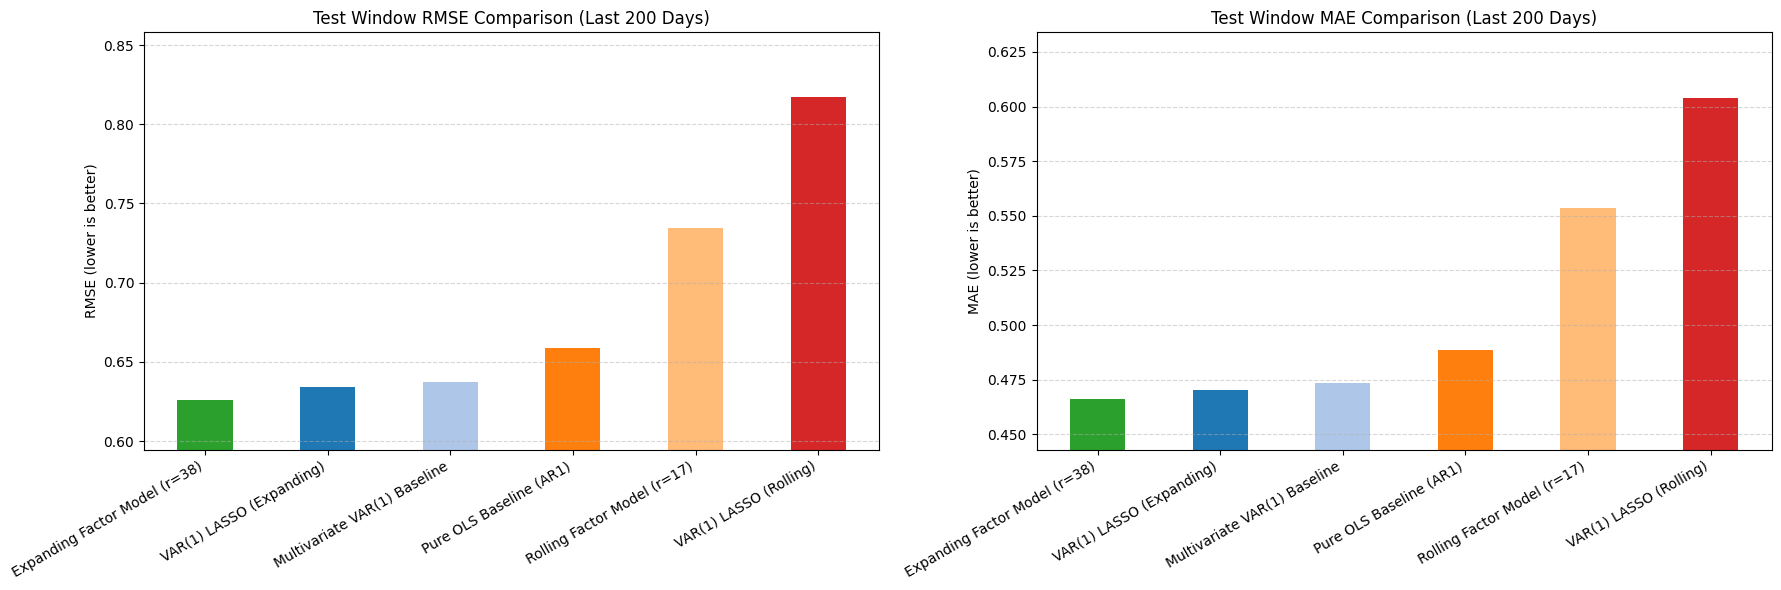

In [ ]:
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

print("=== Starting Unified Out-of-Sample Evaluation (Last 200 Days Test Window) ===")

# Ensure data and dimensions - using X_df directly instead of log
T_total, N = X_df.shape
t_start = 1375
val_len = 800
n_oos = T_total - t_start
eval_dates = X_df.index[t_start + 1:]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
X_raw = torch.tensor(X_df.values, dtype=torch.float32, device=device)

# -----------------------------------------------------
# 1. Pure OLS Baseline (AR1) & Multivariate VAR(1) Baseline
# -----------------------------------------------------
print("Running OLS Baseline (AR1) & Multivariate VAR(1) Baseline...")
ols_errors = []
var_errors = []

for t in range(t_start, T_total):
    X_win = X_raw[:t]
    mean_t = X_win.mean(dim=0, keepdim=True)
    std_t = X_win.std(dim=0, keepdim=True)
    std_t[std_t == 0.0] = 1.0
    X_norm = (X_win - mean_t) / std_t
    x_actual_norm = (X_raw[t : t + 1] - mean_t) / std_t

    Y_train = X_norm[1:, :]
    F_train = X_norm[:-1, :]
    f_latest = X_norm[-1:, :]

    # (A) Pure OLS (AR1)
    num = (F_train * Y_train).sum(dim=0)
    den = (F_train ** 2).sum(dim=0)
    den[den == 0.0] = 1.0
    Beta_ols = num / den
    ols_errors.append((x_actual_norm - f_latest * Beta_ols).cpu().numpy()[0])

    # (B) VAR(1) Baseline
    FtF = F_train.T @ F_train
    FtY = F_train.T @ Y_train
    Beta_VAR = torch.linalg.solve(FtF, FtY)
    var_errors.append((x_actual_norm - f_latest @ Beta_VAR).cpu().numpy()[0])

ols_test_errs = np.array(ols_errors)[val_len:]
var_test_errs = np.array(var_errors)[val_len:]

ols_rmse = np.sqrt(np.mean(ols_test_errs ** 2))
ols_mae = np.mean(np.abs(ols_test_errs))
var_rmse = np.sqrt(np.mean(var_test_errs ** 2))
var_mae = np.mean(np.abs(var_test_errs))

# -----------------------------------------------------
# 2. Optimal Rolling & Expanding Factor Models
# -----------------------------------------------------
print("Running Factor Models (Expanding r=38, Rolling r=17)...")
# Cleanly instantiate FactorModelEvaluator statically to avoid namespace clashes
factor_evaluator = FactorModelEvaluator(X_df, r_max=40, n_eval=800, window_size=500)

exp_test_metrics = factor_evaluator.evaluate_performance(exp_errors, start_idx=600, end_idx=800)
roll_test_metrics = factor_evaluator.evaluate_performance(roll_errors, start_idx=600, end_idx=800)

test_rmse_exp = exp_test_metrics.loc[best_exp_r, 'RMSE']
test_mae_exp = exp_test_metrics.loc[best_exp_r, 'MAE']
test_rmse_roll = roll_test_metrics.loc[best_roll_r, 'RMSE']
test_mae_roll = roll_test_metrics.loc[best_roll_r, 'MAE']

# -----------------------------------------------------
# 3. VAR(1) LASSO Models (Expanding & Rolling)
# -----------------------------------------------------
print("Extracting VAR(1) LASSO performance...")
lasso_rmse_exp = res_expanding['test_rmse']
lasso_mae_exp = res_expanding['test_mae']
lasso_rmse_roll = res_rolling['test_rmse']
lasso_mae_roll = res_rolling['test_mae']

# -----------------------------------------------------
# 4. Consolidate and Plot Results
# -----------------------------------------------------
results_dict = {
    'VAR(1) LASSO (Expanding)': [lasso_rmse_exp, lasso_mae_exp],
    'Multivariate VAR(1) Baseline': [var_rmse, var_mae],
    f'Expanding Factor Model (r={best_exp_r})': [test_rmse_exp, test_mae_exp],
    'Pure OLS Baseline (AR1)': [ols_rmse, ols_mae],
    f'Rolling Factor Model (r={best_roll_r})': [test_rmse_roll, test_mae_roll],
    'VAR(1) LASSO (Rolling)': [lasso_rmse_roll, lasso_mae_roll]
}

comparison_summary = pd.DataFrame.from_dict(
    results_dict,
    orient='index',
    columns=['Out-of-Sample RMSE', 'Out-of-Sample MAE']
).sort_values('Out-of-Sample RMSE')

print("\n=== Consolidated 6-Model Comparison Table (Standardized Scale) ===")
display(comparison_summary)

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
colors = ['#2ca02c', '#1f77b4', '#aec7e8', '#ff7f0e', '#ffbb78', '#d62728']

# RMSE Bar Chart
ax1.bar(comparison_summary.index, comparison_summary['Out-of-Sample RMSE'], color=colors[:len(comparison_summary)], width=0.45)
ax1.set_title('Test Window RMSE Comparison (Last 200 Days)')
ax1.set_ylabel('RMSE (lower is better)')
ax1.set_ylim(comparison_summary['Out-of-Sample RMSE'].min() * 0.95, comparison_summary['Out-of-Sample RMSE'].max() * 1.05)
ax1.grid(True, linestyle='--', alpha=0.5, axis='y')
ax1.set_xticks(range(len(comparison_summary)))
ax1.set_xticklabels(comparison_summary.index, rotation=30, ha='right')

# MAE Bar Chart
ax2.bar(comparison_summary.index, comparison_summary['Out-of-Sample MAE'], color=colors[:len(comparison_summary)], width=0.45)
ax2.set_title('Test Window MAE Comparison (Last 200 Days)')
ax2.set_ylabel('MAE (lower is better)')
ax2.set_ylim(comparison_summary['Out-of-Sample MAE'].min() * 0.95, comparison_summary['Out-of-Sample MAE'].max() * 1.05)
ax2.grid(True, linestyle='--', alpha=0.5, axis='y')
ax2.set_xticks(range(len(comparison_summary)))
ax2.set_xticklabels(comparison_summary.index, rotation=30, ha='right')

plt.tight_layout()
plt.show()

In [ ]:
import time
import numpy as np
from sklearn.linear_model import Lasso

# --- Diagnostic & Robustness Check of Numba coordinate descent ---
def run_diagnostics():
    print("=== Running Numba Coordinate Descent Diagnostics ===")

    # Generate a small synthetic dataset representing one step of the loop
    np.random.seed(42)
    M, N = 500, 40
    X_test = np.ascontiguousarray(np.random.randn(M, N))
    y_test = np.ascontiguousarray(np.random.randn(M))

    # Precompute Gram matrix and cross correlation
    G = np.dot(X_test.T, X_test) / M
    xty = np.dot(X_test.T, y_test) / M

    # Choose an intermediate alpha value
    alpha = 0.05
    beta_init = np.zeros(N, dtype=np.float64)

    # Time Numba single solver (first run has compile overhead, second is raw speed)
    _ = numba_single_lasso_with_warm_start(G, xty, alpha, beta_init, max_iter=1000, tol=1e-5)

    t0 = time.perf_counter()
    beta_numba = numba_single_lasso_with_warm_start(G, xty, alpha, beta_init, max_iter=1000, tol=1e-5)
    t_numba = time.perf_counter() - t0

    # Compare with Scikit-Learn's highly optimized C-based Lasso solver
    clf = Lasso(alpha=alpha, fit_intercept=False, max_iter=1000, tol=1e-5)
    t1 = time.perf_counter()
    clf.fit(X_test, y_test)
    t_sklearn = time.perf_counter() - t1
    beta_sklearn = clf.coef_

    # Compute metrics
    max_diff = np.max(np.abs(beta_numba - beta_sklearn))
    sparsity_numba = np.sum(beta_numba == 0.0)

    print(f"Numba Single Solver Execution Time: {t_numba:.6f} seconds")
    print(f"Sklearn Solver Execution Time:      {t_sklearn:.6f} seconds")
    print(f"Maximum coefficient discrepancy:    {max_diff:.2e}")
    print(f"Identified Sparsity (Zero Coefs):   {sparsity_numba} out of {N}")

    if max_diff > 1e-3:
        print("WARNING: Divergence or mathematical error detected between Numba and Sklearn!")
    else:
        print("SUCCESS: Mathematical convergence and solution matching verified.")

run_diagnostics()